## ML Project
 7th September 2026
 
*Wednesday*

# import important librayries

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_diabetes, load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_curve, auc)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# Create a folder to store trained artifacts (models + schemas)
ARTIFACT_DIR = 'model_artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)
RANDOM_STATE = 42  # fixed seed for reproducibility — always set this in professional ML work


print("Setup complete. Artifacts will be saved to:", os.path.abspath(ARTIFACT_DIR))

Setup complete. Artifacts will be saved to: D:\classes\ML\code\second\model_artifacts


# Chek data

In [43]:
df=pd.read_csv('student_placement_prediction_dataset_2026.csv')
df.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [44]:
df.drop(columns=['student_id'],inplace=True)

In [45]:
df.head()

,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   age                        100000 non-null  int64  
 1   gender                     100000 non-null  object 
 2   cgpa                       100000 non-null  float64
 3   branch                     100000 non-null  object 
 4   college_tier               100000 non-null  object 
 5   internships_count          100000 non-null  int64  
 6   projects_count             100000 non-null  int64  
 7   certifications_count       100000 non-null  int64  
 8   coding_skill_score         100000 non-null  float64
 9   aptitude_score             100000 non-null  float64
 10  communication_skill_score  100000 non-null  float64
 11  logical_reasoning_score    100000 non-null  float64
 12  hackathons_participated    100000 non-null  int64  
 13  github_repos               100

## Missing values

In [47]:
missing = df.isnull().sum()
print("Total missing values:", missing.sum())
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

## Duplicated rows

In [48]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


# Statical summry

In [49]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,21.005740,1.999562,18.0,19.000000,21.000000,23.000000,24.00
cgpa,100000.0,7.496890,0.992834,4.5,6.820000,7.500000,8.180000,10.00
internships_count,100000.0,1.502230,1.225280,0.0,1.000000,1.000000,2.000000,8.00
projects_count,100000.0,3.001860,1.731764,0.0,2.000000,3.000000,4.000000,13.00
certifications_count,100000.0,2.005150,1.416553,0.0,1.000000,2.000000,3.000000,11.00
coding_skill_score,100000.0,69.825326,14.694618,20.0,59.807945,70.006250,80.058762,100.00
aptitude_score,100000.0,64.988108,14.844093,20.0,54.894600,65.011394,75.079266,100.00
communication_skill_score,100000.0,67.960744,13.846636,20.0,58.587535,67.973221,77.503749,100.00
logical_reasoning_score,100000.0,65.931696,14.826790,20.0,55.940547,66.003829,76.113705,100.00
hackathons_participated,100000.0,1.000690,0.997908,0.0,0.000000,1.000000,2.000000,8.00


placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


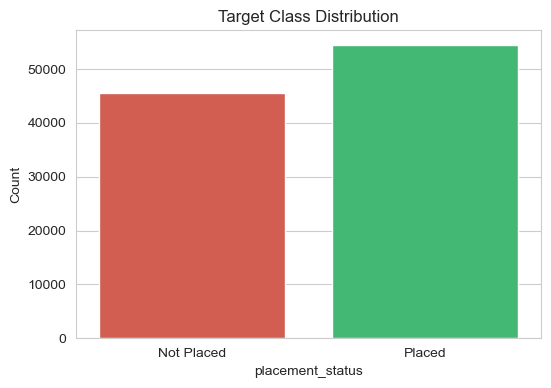


Class balance ratio: 0.84 : 1
Dataset is moderately imbalanced — stratified splitting will be used.


In [50]:
target_counts = df["placement_status"].value_counts()
print(target_counts)

plt.figure(figsize=(6,4))
sns.countplot(x="placement_status", data=df, palette=["#e74c3c", "#2ecc71"])
plt.xticks([0,1], ["Not Placed", "Placed"])
plt.title("Target Class Distribution")
plt.ylabel("Count")
plt.show()

print(f"\nClass balance ratio: {target_counts[1]/target_counts[0]:.2f} : 1")
print("Dataset is moderately imbalanced — stratified splitting will be used.")


In [51]:
df.head().T

,0,1,2,3,4
age,24,21,22,24,20
gender,Male,Male,Female,Male,Female
cgpa,7.53,7.92,8.6,6.68,8.43
branch,IT,CSE,EEE,CSE,IT
college_tier,Tier 2,Tier 2,Tier 1,Tier 1,Tier 3
internships_count,4,1,0,0,1
projects_count,6,3,1,2,4
certifications_count,1,6,1,2,3
coding_skill_score,99.238568,80.966123,49.177184,79.359084,65.018573
aptitude_score,81.707722,63.116715,48.658753,66.376653,61.274985


### Univariate Analysis  Feature Distributions

We inspect a handful of key features to understand their spread and skewness.

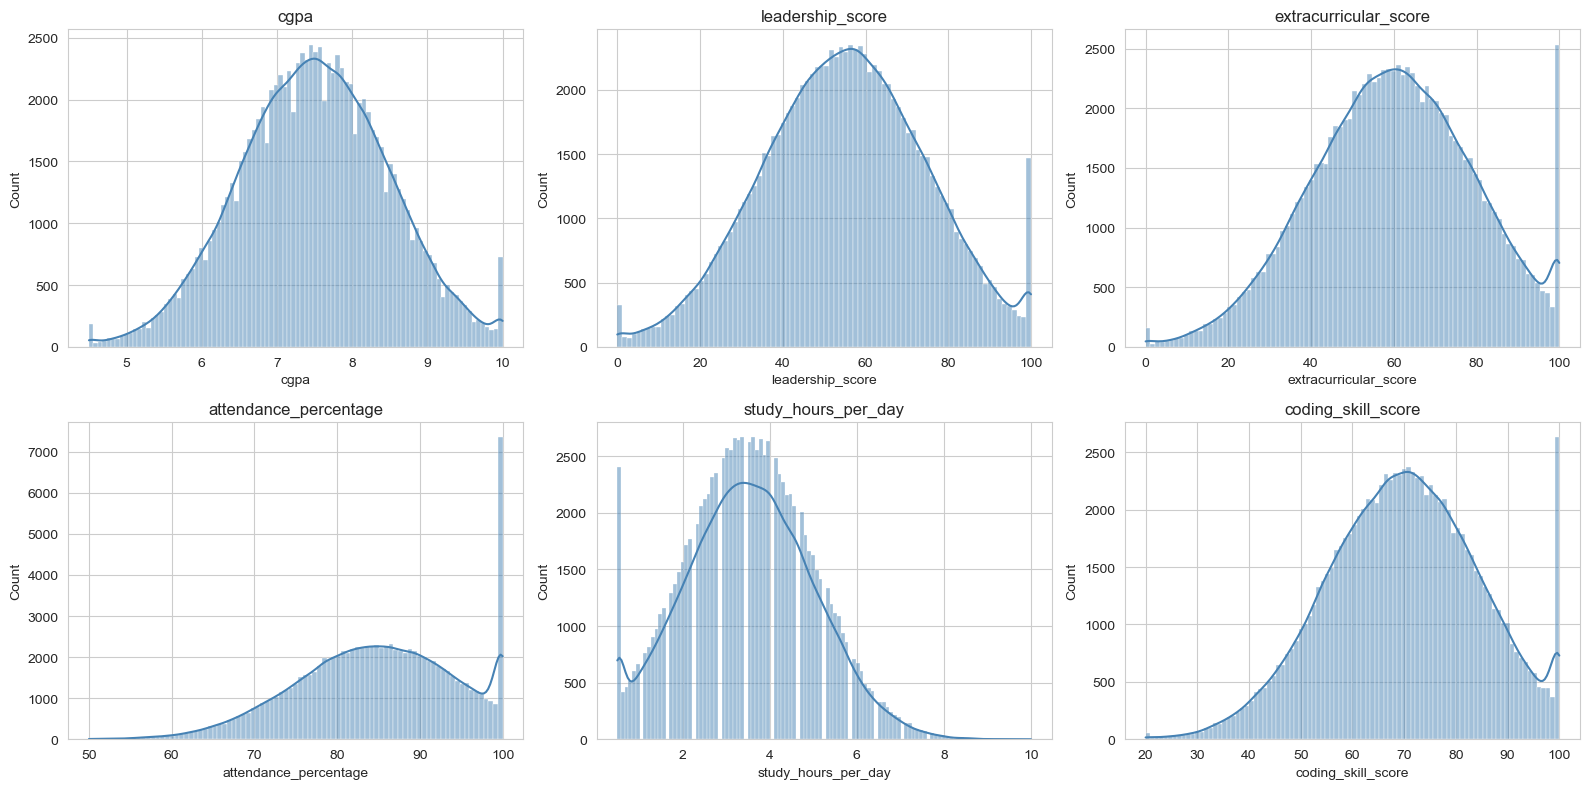

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sample_features = ["cgpa", "leadership_score", "extracurricular_score",
                    "attendance_percentage", "study_hours_per_day", "coding_skill_score"]

for ax, feature in zip(axes.flatten(), sample_features):
    sns.histplot(df[feature], kde=True, ax=ax, color="steelblue")
    ax.set_title(feature)

plt.tight_layout()
plt.show()

### Bivariate Analysis  Features vs Target

Boxplots show how feature values differ between malignant and benign tumors features with clear separation are likely strong predictors.


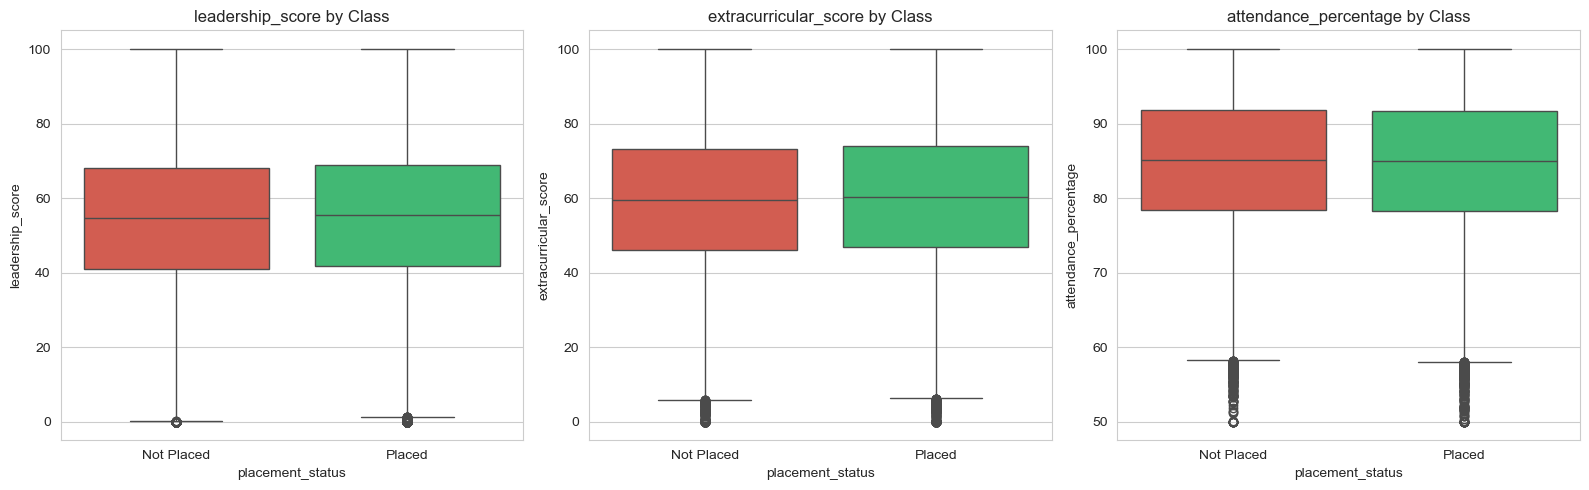

In [53]:
fig, axes = plt.subplots(1,3, figsize=(16, 5))
for ax, feature in zip(axes,["leadership_score", "extracurricular_score","attendance_percentage"]):
    sns.boxplot(x="placement_status", y=feature, data=df, ax=ax, palette=["#e74c3c", "#2ecc71"])
    ax.set_xticklabels(["Not Placed", "Placed"])
    ax.set_title(f"{feature} by Class")

plt.tight_layout()
plt.show()

### Correlation Analysis

High correlation between features (multicollinearity) can destabilize linear models and inflate coefficient variance. We visualize correlation among the "mean" features.


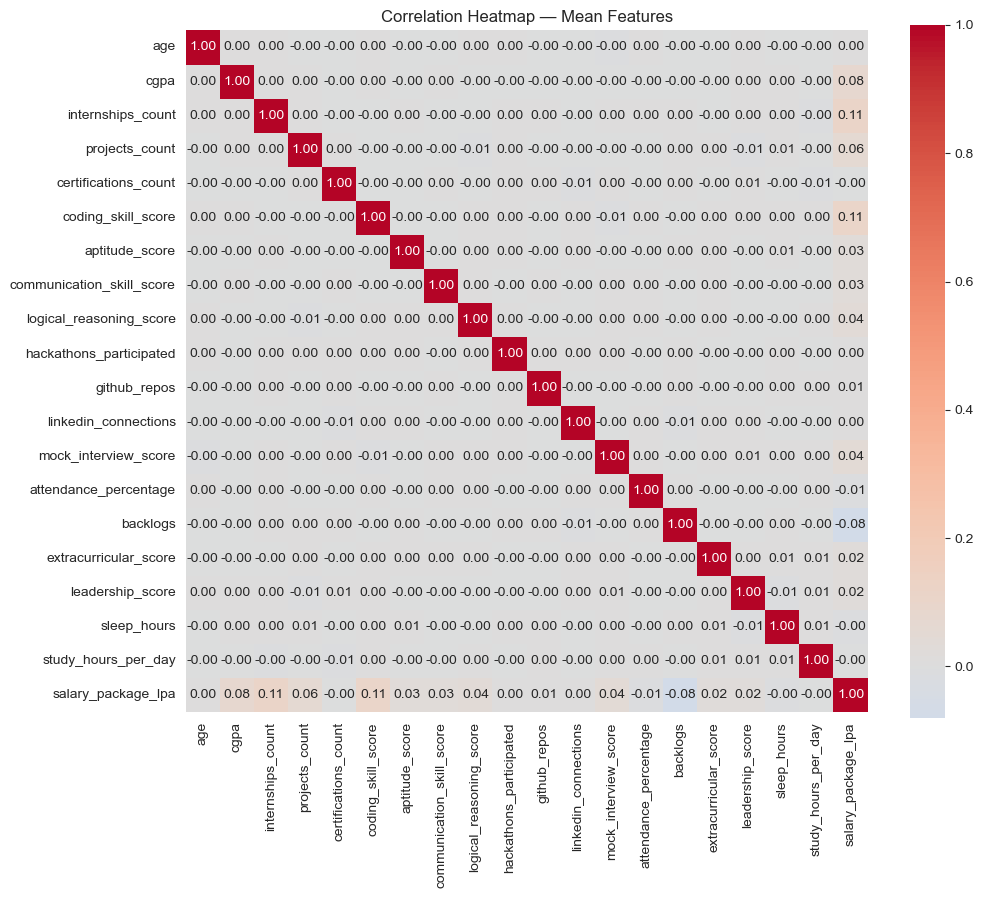

In [54]:
mean_features = [c for c in df.columns]
corr = df.corr(numeric_only=True)
plt.figure(figsize=(11,9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Mean Features")
plt.show()

### Outlier Detection (IQR Method)

Outliers can distort distance-based algorithms (KNN, SVM) and skew scaling. We use the Interquartile Range (IQR) method: any point beyond `1.5 * IQR` from Q1/Q3 is flagged.


In [55]:
def count_outliers_iqr(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return ((series < lower) | (series > upper)).sum()

numeric_df = df.select_dtypes(include='number')
outlier_summary = numeric_df.apply(count_outliers_iqr).sort_values(ascending=False)

print("Top 10 features by outlier count:")
outlier_summary.head(10)

Top 10 features by outlier count:


internships_count          6565
github_repos               2163
backlogs                   1481
projects_count             1176
certifications_count        438
mock_interview_score        399
attendance_percentage       373
logical_reasoning_score     362
cgpa                        361
aptitude_score              355
dtype: int64

In [57]:
df.head().T

,0,1,2,3,4
age,24,21,22,24,20
gender,Male,Male,Female,Male,Female
cgpa,7.53,7.92,8.6,6.68,8.43
branch,IT,CSE,EEE,CSE,IT
college_tier,Tier 2,Tier 2,Tier 1,Tier 1,Tier 3
internships_count,4,1,0,0,1
projects_count,6,3,1,2,4
certifications_count,1,6,1,2,3
coding_skill_score,99.238568,80.966123,49.177184,79.359084,65.018573
aptitude_score,81.707722,63.116715,48.658753,66.376653,61.274985


## 3. Train-Test Split (Before Scaling/Encoding)

**Critical rule: split the data BEFORE fitting any scaler or encoder.**

If you scale/encode the *entire* dataset first and split afterward, statistics from the test set (mean, std, min, max) leak into training — this is called **data leakage**, and it produces overly optimistic, unrealistic performance estimates.

We use `stratify=y` to preserve the class proportions found in EDA (Section 2.5) in both splits.


In [58]:
X = df.drop(columns=["placement_status", "salary_package_lpa"])
y = df["placement_status"]
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,stratify=y
)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))


Train shape: (80000, 23)
Test shape: (20000, 23)

Train class balance:
 placement_status
Placed        0.544588
Not Placed    0.455412
Name: proportion, dtype: float64

Test class balance:
 placement_status
Placed        0.5446
Not Placed    0.4554
Name: proportion, dtype: float64


In [59]:
df.head()

,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


# Ordinal Encoding
for colege_tier and branch

In [60]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# 1. Encoding se pehle ki original Text values (df se) save karna
cols = ["college_tier", "branch"]
before_df = df.loc[X_train.index, cols].head().copy()

# 2. Ordinal Encoder apply karna
oe = OrdinalEncoder()
X_train[cols] = oe.fit_transform(X_train[cols])
X_test[cols] = oe.transform(X_test[cols])

# 3. Encoding ke baad ka data
after_df = X_train[cols].head()

# 4. Pehle (Text) aur Baad (Numbers) ko ek hi table mein dikhana
comparison_df = pd.concat(
    [before_df.reset_index(drop=True), after_df.reset_index(drop=True)],
    axis=1,
)

# Roman Urdu mein Column Names set karna
comparison_df.columns = [
    "college_tier (before Encoding)",
    "branch (before Encoding)",
    "college_tier (After Encoding)",
    "branch (After Encoding)",
]

comparison_df.head(15)

,college_tier (before Encoding),branch (before Encoding),college_tier (After Encoding),branch (After Encoding)
0,Tier 1,IT,0.0,4.0
1,Tier 3,CSE,2.0,0.0
2,Tier 2,Mechanical,1.0,5.0
3,Tier 3,IT,2.0,4.0
4,Tier 2,CSE,1.0,0.0


# One Hot Encoding 
for Gender and volunteer_Experience

In [61]:
from sklearn.preprocessing import OneHotEncoder

# 1. Encodable columns
ohe_cols = [
    col for col in ["gender", "volunteer_experience"] if col in X_train.columns
]

if ohe_cols:
    # Encoding se pehle ki original values save karein
    before_df = X_train[ohe_cols].head().reset_index(drop=True)

    # 2. OneHotEncoder apply karein
    ohe = OneHotEncoder(
        sparse_output=False, drop="first", handle_unknown="ignore"
    )
    X_train_ohe = ohe.fit_transform(X_train[ohe_cols])
    X_test_ohe = ohe.transform(X_test[ohe_cols])

    encoded_feature_names = ohe.get_feature_names_out(ohe_cols)

    df_train_ohe = pd.DataFrame(
        X_train_ohe, columns=encoded_feature_names, index=X_train.index
    )
    df_test_ohe = pd.DataFrame(
        X_test_ohe, columns=encoded_feature_names, index=X_test.index
    )

    # Encoding ke baad ki values
    after_df = df_train_ohe.head().reset_index(drop=True)

    # Main X_train / X_test ko update karein
    X_train = pd.concat(
        [X_train.drop(columns=ohe_cols), df_train_ohe], axis=1
    )
    X_test = pd.concat([X_test.drop(columns=ohe_cols), df_test_ohe], axis=1)

    # 3. Before aur After ko aik sath dikhane ke liye combine karein
    comparison_df = pd.concat([before_df, after_df], axis=1)
    display(comparison_df)

,gender,volunteer_experience,gender_Male,volunteer_experience_Yes
0,Male,Yes,1.0,1.0
1,Male,Yes,1.0,1.0
2,Male,No,1.0,0.0
3,Female,No,0.0,0.0
4,Female,Yes,0.0,1.0


## Normalization (Min-Max Scaling)
Normalization humaray data ko 0 sya 1 ki rang may kar daytha hay 

In [62]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =scaler.transform(X_test)

sample_cols = [
    "age",
    "cgpa",
    "coding_skill_score",
    "attendance_percentage",
    "sleep_hours",
]

print(' '*20,"--- Before Normalization ---")
display(X_train[sample_cols].head())

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
print(' '*20,"--- After Normalization ---")
display(X_train_scaled_df[sample_cols].head())

                     --- Before Normalization ---


,age,cgpa,coding_skill_score,attendance_percentage,sleep_hours
12685,21,8.46,67.843235,100.000000,5.3
72956,19,8.82,75.622987,89.302634,7.7
75845,23,6.47,70.626704,100.000000,9.8
83333,22,7.76,70.343441,81.783848,7.9
76658,19,9.50,48.464530,68.460617,3.5


                     --- After Normalization ---


,age,cgpa,coding_skill_score,attendance_percentage,sleep_hours
0,0.500000,0.720000,0.598040,1.000000,0.328571
1,0.166667,0.785455,0.695287,0.786053,0.671429
2,0.833333,0.358182,0.632834,1.000000,0.971429
3,0.666667,0.592727,0.629293,0.635677,0.700000
4,0.166667,0.909091,0.355807,0.369212,0.071429


##  Standardization (Z-score Scaling)
standardization humary data kay mean ko 0 or standar division ko 1 kar lay tha hay 

In [63]:
std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)

sample_cols = ["age","cgpa","coding_skill_score","attendance_percentage","sleep_hours",]

mean_before = X_train[sample_cols].mean()
std_before = X_train[sample_cols].std()

X_train_std_df = pd.DataFrame(X_train_std, columns=X_train.columns)
X_test_std = std_scaler.transform(X_test)
mean_after = X_train_std_df[sample_cols].mean()
std_after = X_train_std_df[sample_cols].std()

comparison_df = pd.DataFrame({
    "Mean (Before)": mean_before.round(2),
    "Std Dev (Before)": std_before.round(2),
    "Mean (After)": mean_after.round(2),
    "Std Dev (After)": std_after.round(2),
})

comparison_df

,Mean (Before),Std Dev (Before),Mean (After),Std Dev (After)
age,21.01,2.00,-0.0,1.0
cgpa,7.50,0.99,0.0,1.0
coding_skill_score,69.81,14.67,0.0,1.0
attendance_percentage,84.72,9.42,0.0,1.0
sleep_hours,6.98,1.47,0.0,1.0


## Cross Validation
    data ko mukhthlif hisso may banth kar wos ki tarianing karht hay.
    
    model ko overfitting say buchatha hay 

In [64]:
model = LogisticRegression(max_iter=1000)
cv_scores = cross_val_score(model, X_train_std, y_train, cv=5)

print("5-Folds Display Scores:", cv_scores.round(4))
print("Mean Accuracy Score:", np.mean(cv_scores).round(4))
print("Standard Deviation (Std):", np.std(cv_scores).round(4))

5-Folds Display Scores: [0.567  0.5716 0.5739 0.5641 0.5709]
Mean Accuracy Score: 0.5695
Standard Deviation (Std): 0.0035


##  Regularization

**Definition:** Regularization adds a penalty term to a model's loss function to discourage overly complex models (large coefficient magnitudes), reducing **overfitting** and improving generalization to unseen data.

**Types:**

| Type | Penalty term | Effect |
|---|---|---|
| **L1 (Lasso)** | $\lambda \sum |w_i|$ | Can shrink some coefficients to exactly **0** → performs automatic feature selection |
| **L2 (Ridge)** | $\lambda \sum w_i^2$ | Shrinks all coefficients smoothly toward 0, rarely exactly 0 |
| **ElasticNet** | Mix of L1 + L2 | Balances feature selection and coefficient shrinkage |

**Why it matters:**
- Without regularization, models (especially linear ones) can fit noise in the training data, achieving high training accuracy but poor test accuracy — the classic overfitting symptom.
- The regularization strength is controlled by a hyperparameter (`C` in scikit-learn's `LogisticRegression`, which is the **inverse** of regularization strength  smaller `C` means **stronger** regularization).

We compare L1 vs L2 regularization on our standardized training data.


In [65]:
results = []

for penalty, solver in [("l1", "liblinear"), ("l2", "liblinear")]:
    model = LogisticRegression(
        penalty=penalty, solver=solver, C=1.0,
        max_iter=10000, random_state=RANDOM_STATE
    )
    scores = cross_val_score(model, X_train_std, y_train, cv=5, scoring="accuracy")
    results.append({"Penalty": penalty.upper(), "Mean CV Accuracy": scores.mean(), "Std": scores.std()})

reg_results_df = pd.DataFrame(results)
reg_results_df


,Penalty,Mean CV Accuracy,Std
0,L1,0.569487,0.003514
1,L2,0.569550,0.003466


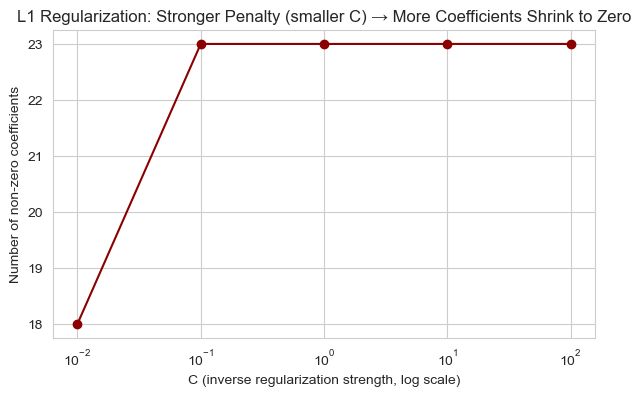

In [66]:
# Demonstrate effect of regularization STRENGTH (C) on number of zeroed-out coefficients (L1)
C_values = [0.01, 0.1, 1, 10, 100]
nonzero_counts = []

for C in C_values:
    model = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_std, y_train)
    nonzero_counts.append(np.sum(model.coef_ != 0))

plt.figure(figsize=(7,4))
plt.plot(C_values, nonzero_counts, marker="o", color="darkred")
plt.xscale("log")
plt.xlabel("C (inverse regularization strength, log scale)")
plt.ylabel("Number of non-zero coefficients")
plt.title("L1 Regularization: Stronger Penalty (smaller C) → More Coefficients Shrink to Zero")
plt.show()

## Model Training

Classificatin

In [67]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 5 Supervised Classification Models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=10000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    # SVC ko fast banane ke liye max_iter limit lagaein
    "Support Vector Machine": SVC(
        kernel="linear",
        max_iter=1000,
        probability=True,
        class_weight="balanced",
        random_state=42,
)
}

trained_models = {}

# Training Loop with Time Tracking
start_total = time.time()
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_std, y_train)
    t1 = time.time()
    trained_models[name] = model
    print(f"✅ {name} trained successfully in {t1 - t0:.2f} seconds.")

print(
    f"\n🎉 All 5 models trained successfully! Total time: {time.time() - start_total:.2f} seconds."
)

✅ Logistic Regression trained successfully in 0.39 seconds.
✅ Decision Tree trained successfully in 6.94 seconds.
✅ Random Forest trained successfully in 17.01 seconds.
✅ K-Nearest Neighbors trained successfully in 0.36 seconds.
✅ Support Vector Machine trained successfully in 148.87 seconds.

🎉 All 5 models trained successfully! Total time: 173.57 seconds.


## Model Training

Regression

In [68]:
# 1. Train Data
X_train_p = X_train[df.loc[X_train.index, 'salary_package_lpa'] > 0]
y_train_p = df.loc[X_train_p.index, 'salary_package_lpa']

# 2. Test Data
X_test_p = X_test[df.loc[X_test.index, 'salary_package_lpa'] > 0]
y_test_p = df.loc[X_test_p.index, 'salary_package_lpa']

reg_models = {
    "Linear Regression": LinearRegression(),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

for name, model in reg_models.items():
    model.fit(X_train_p, y_train_p)
    print(f"✅ {name} Train Succesfully!")

✅ Linear Regression Train Succesfully!
✅ Gradient Boosting Train Succesfully!
✅ Random Forest Train Succesfully!


In [69]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

results = []

for name, model in reg_models.items():
    y_pred = model.predict(X_test_p)
    
    r2 = r2_score(y_test_p, y_pred)
    mae = mean_absolute_error(y_test_p, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_p, y_pred))
    
    results.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "MAE (LPA)": round(mae, 4),
        "RMSE (LPA)": round(rmse, 4)
    })

reg_summary_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)

print("=== Placed Students — Regression Results ===")
display(reg_summary_df)

best_model_name = reg_summary_df.loc[0, "Model"]
best_r2 = reg_summary_df.loc[0, "R2 Score"]
print(f"\n🏆 your best model: '{best_model_name}' (R2 Score: {best_r2})")

=== Placed Students — Regression Results ===


,Model,R2 Score,MAE (LPA),RMSE (LPA)
0,Linear Regression,0.6028,0.7958,0.9985
1,Gradient Boosting,0.5992,0.7993,1.0030
2,Random Forest,0.5905,0.8076,1.0138



🏆 your best model: 'Linear Regression' (R2 Score: 0.6028)


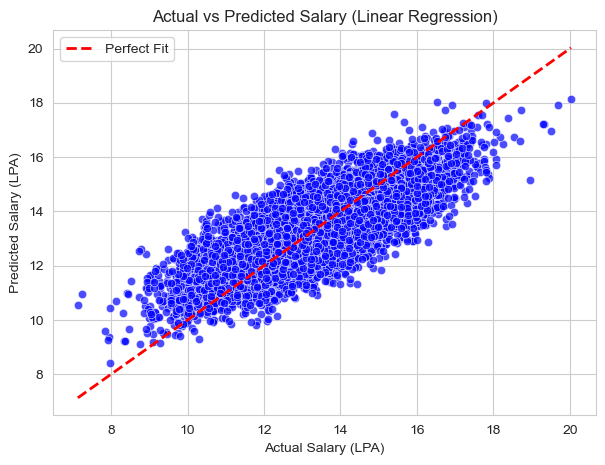

In [70]:
# 1. Linear Regression کی پرڈکشنز
best_model = reg_models["Linear Regression"]
y_pred_best = best_model.predict(X_test_p)

# 2. Scatter Plot بنانا
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test_p, y=y_pred_best, color="blue", alpha=0.7)

# Perfect Predictions کی 45-degree ریڈ لائن
plt.plot([y_test_p.min(), y_test_p.max()], [y_test_p.min(), y_test_p.max()], "r--", lw=2, label="Perfect Fit")

plt.xlabel("Actual Salary (LPA)")
plt.ylabel("Predicted Salary (LPA)")
plt.title("Actual vs Predicted Salary (Linear Regression)")
plt.legend()
plt.grid(True)
plt.show()

## 10. Model Evaluation Metrics

No single metric tells the full story, especially with imbalanced classes (Section 2.5). We compute the standard suite of classification metrics for each model:

| Metric | Formula / Meaning | When it matters most |
|---|---|---|
| **Accuracy** | (TP+TN) / Total | Balanced classes only  misleading on imbalanced data |
| **Precision** | TP / (TP+FP) | When false positives are costly (e.g. flagging healthy patients as sick) |
| **Recall (Sensitivity)** | TP / (TP+FN) | When false negatives are costly (e.g. missing an actual cancer case) |
| **F1-Score** | Harmonic mean of Precision & Recall | Balances both, useful for imbalanced data |
| **ROC-AUC** | Area under the ROC curve | Measures ranking quality across all thresholds, threshold-independent |
| **Confusion Matrix** | TP, TN, FP, FN breakdown | Full picture of error types |

In medical diagnosis (our use case), **Recall is often prioritized**  missing a malignant tumor (false negative) is typically far more dangerous than a false alarm (false positive).


In [71]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

eval_results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_std)
    y_proba = model.predict_proba(X_test_std)[:, 1]

    eval_results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, pos_label="Placed"),
            "Recall": recall_score(y_test, y_pred, pos_label="Placed"),
            "F1-Score": f1_score(y_test, y_pred, pos_label="Placed"),
            "ROC-AUC": roc_auc_score((y_test == "Placed").astype(int), y_proba),
        }
    )

eval_df = pd.DataFrame(eval_results).set_index("Model").round(4)
display(eval_df)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.5576,0.5989,0.5684,0.5832,0.5854
Decision Tree,0.5148,0.5543,0.5564,0.5554,0.5107
Random Forest,0.5526,0.5687,0.7384,0.6426,0.5578
K-Nearest Neighbors,0.5190,0.5540,0.5995,0.5759,0.5166
Support Vector Machine,0.5140,0.5490,0.6025,0.5745,0.5064


### Confusion Matrices

Visualizing exactly where each model's errors occur false positives vs false negatives.


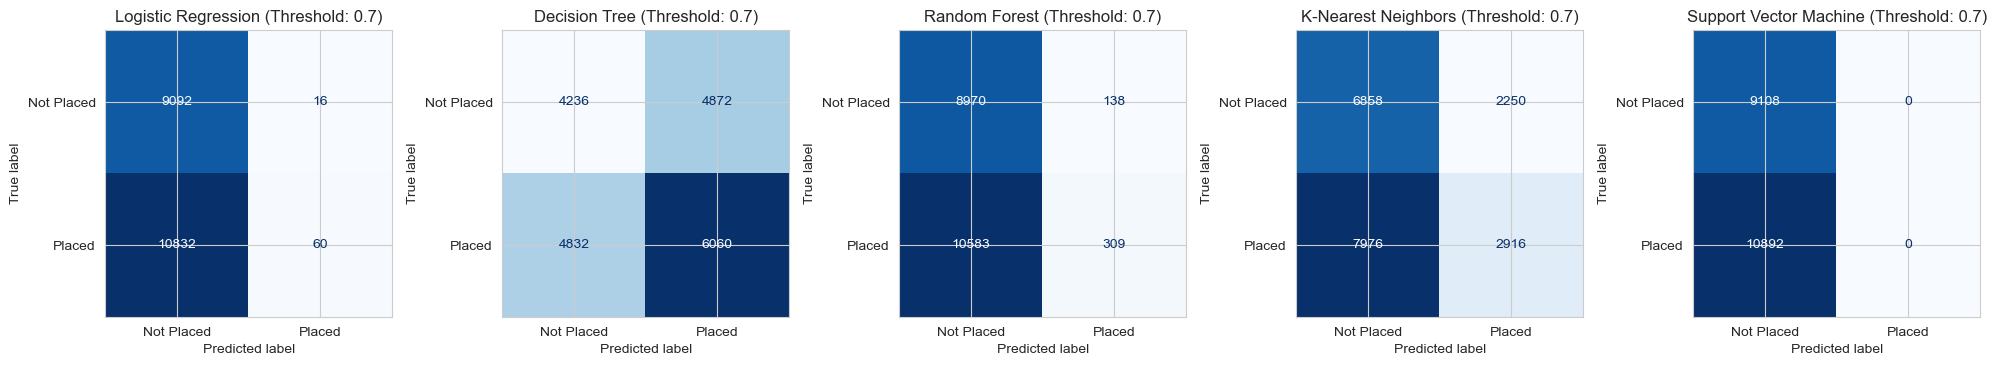

In [72]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Is ke baad baqi aap ka confusion matrix wala loop chalega...
fig, axes = plt.subplots(1, len(trained_models), figsize=(20, 4))

threshold = 0.70
for ax, (name, model) in zip(axes, trained_models.items()):
    y_proba = model.predict_proba(X_test_std)[:, 1]
    y_pred_custom = (y_proba >= threshold).astype(int)
    y_pred_labels = [
        "Placed" if p == 1 else "Not Placed" for p in y_pred_custom
    ]

    cm = confusion_matrix(
        y_test, y_pred_labels, labels=["Not Placed", "Placed"]
    )
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Not Placed", "Placed"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (Threshold: {threshold})")

plt.tight_layout()
plt.show()

### ROC Curves

The ROC curve plots True Positive Rate vs False Positive Rate across all classification thresholds. A curve closer to the top-left corner (AUC closer to 1.0) indicates better discrimination ability.


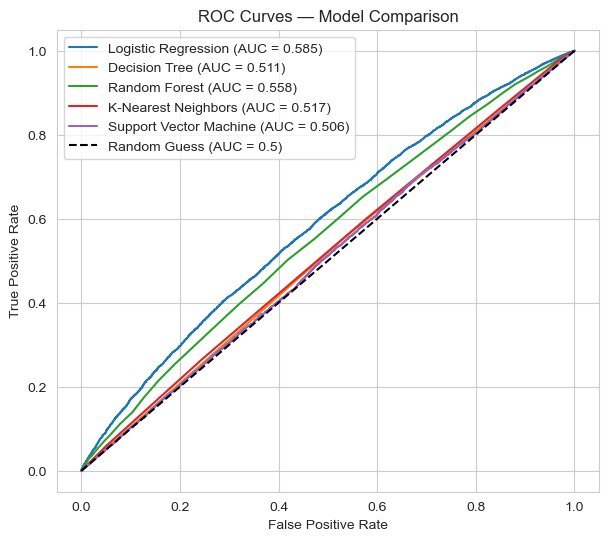

In [73]:
plt.figure(figsize=(7, 6))

for name, model in trained_models.items():
    # X_test_std istemaal karein
    y_proba = model.predict_proba(X_test_std)[:, 1]

    # y_test ko 0 aur 1 mein map karein
    y_true_num = (y_test == "Placed").astype(int)

    fpr, tpr, _ = roc_curve(y_true_num, y_proba)
    auc_val = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.show()

### Full Classification Report (Best Model)

In [74]:
y_pred_best = trained_models["Logistic Regression"].predict(X_test_std)

# Classification Report print karein
print("=" * 60)
print("       FULL CLASSIFICATION REPORT (BEST MODEL)")
print("=" * 60)
print(
    classification_report(
        y_test, y_pred_best, target_names=["Not Placed", "Placed"]
    )
)

       FULL CLASSIFICATION REPORT (BEST MODEL)
              precision    recall  f1-score   support

  Not Placed       0.51      0.54      0.53      9108
      Placed       0.60      0.57      0.58     10892

    accuracy                           0.56     20000
   macro avg       0.56      0.56      0.56     20000
weighted avg       0.56      0.56      0.56     20000



##  Hyperparameter Tuning with Cross Validation

We combine **Cross Validation ** with **Regularization (Section 8)** using `GridSearchCV` to systematically search for the best regularization strength and penalty type for Logistic Regression — this is how CV and regularization are used together in real, professional ML workflows.


In [75]:
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import GridSearchCV

# Custom F1 Scorer banayein jo 'Placed' ko target samjhe
f1_scorer = make_scorer(f1_score, pos_label="Placed")

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],  
    "solver": ["liblinear"],
    "class_weight": ["balanced"],
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=10000),
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer,  # Yahan custom scorer pass kiya
    n_jobs=-1,
)

grid_search.fit(X_train_std, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

best_log_reg = grid_search.best_estimator_
trained_models["Logistic Regression (Tuned)"] = best_log_reg

Best Parameters: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1-Score: 0.5868


In [40]:
final_model = grid_search.best_estimator_
y_pred_final = final_model.predict(X_test_std)
y_proba_final = final_model.predict_proba(X_test_std)[:, 1]

print("=== Final Tuned Model — Test Set Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
print(
    f"Precision: {precision_score(y_test, y_pred_final, pos_label='Placed'):.4f}"
)
print(
    f"Recall:    {recall_score(y_test, y_pred_final, pos_label='Placed'):.4f}"
)
print(f"F1-Score:  {f1_score(y_test, y_pred_final, pos_label='Placed'):.4f}")
print(
    f"ROC-AUC:   {roc_auc_score((y_test == 'Placed').astype(int), y_proba_final):.4f}"
)

=== Final Tuned Model — Test Set Performance ===
Accuracy:  0.5576
Precision: 0.5989
Recall:    0.5684
F1-Score:  0.5832
ROC-AUC:   0.5854


## The Key Teaching Concept: Building a Feature Schema

This is the core idea that powers the **dynamic Streamlit UI**. Instead of hardcoding widgets,
we describe each feature as a small JSON object:

```json
{
  "name": "bmi",
  "dtype": "numeric",
  "min": 0.5,
  "max": 15.0,
  "default": 3.8,
  "step": 0.1
}
```

For categorical features we'd instead store `"dtype": "categorical"` with an `"options"` list.
We build one schema per model and save it next to the model file. The Streamlit app will load
`model.pkl` + `schema.json` together and never needs to know the feature names in advance.


In [77]:
import json
import os
import joblib

folder = "MODEL_FILES"

def build_schema(df, step_decimals=2):
    """Auto-generate a schema for numeric columns only."""
    schema = []
    numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

    for feat in numeric_cols:
        col = df[feat]
        step = round((col.max() - col.min()) / 100, step_decimals) or 0.01
        schema.append({
            "name": feat,
            "dtype": "numeric",
            "min": float(col.min()),
            "max": float(col.max()),
            "default": float(col.mean()),
            "step": float(step),
        })
    return schema

# Build & save Regression artifact bundle
reg_schema = {
    "task_type": "regression",
    "model_name": "Linear Regression",
    "target_name": "salary_package_lpa",
    "features": build_schema(X_train_p),
    "requires_scaling": False
}


joblib.dump(reg_models["Linear Regression"], f"{folder}/regression_model.pkl")
with open(f"{folder}/regression_schema.json", "w") as f:
    json.dump(reg_schema, f, indent=2)

print("Saved regression model and schema successfully!")

# Build & save Classification artifact bundle
clf_schema = {
    "task_type": "classification",
    "model_name": "Logistic Regression (Tuned)",
    "target_name": "placement_status",
    "class_names": ["Not Placed", "Placed"],
    "features": build_schema(X_train),
    "requires_scaling": True,
}

# Best Model, Scaler aur Schema save karein
joblib.dump(grid_search.best_estimator_, f"{folder}/classification_model.pkl")
joblib.dump(scaler, f"{folder}/classification_scaler.pkl")

with open(f"{folder}/classification_schema.json", "w") as f:
    json.dump(clf_schema, f, indent=2)

print("Saved classification model, scaler, and schema successfully!")

Saved regression model and schema successfully!
Saved classification model, scaler, and schema successfully!


# Streamlit 

In [79]:
%%writefile streamlit_app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json
import os

st.set_page_config(page_title="Dynamic Placement & Salary Predictor", page_icon="🎓", layout="wide")

ARTIFACT_DIR = "MODEL_FILES"

st.title("🎓 Dynamic Placement & Salary Predictor")
st.caption("This app builds inputs dynamically based on saved JSON schemas.")

# 1. Discover available model tasks
if not os.path.exists(ARTIFACT_DIR):
    st.error(f"Directory `{ARTIFACT_DIR}` not found. Please run training pipeline first.")
    st.stop()

available = [f.replace("_schema.json", "") for f in os.listdir(ARTIFACT_DIR) if f.endswith("_schema.json")]

if not available:
    st.error("No model schemas found. Run the training pipeline first.")
    st.stop()

choice = st.selectbox("Choose a model to use:", available, format_func=lambda x: x.replace("_", " ").title())

# 2. Load model, scaler, and schema
@st.cache_resource
def load_bundle(name):
    model = joblib.load(os.path.join(ARTIFACT_DIR, f"{name}_model.pkl"))
    
    scaler_path = os.path.join(ARTIFACT_DIR, f"{name}_scaler.pkl")
    scaler = joblib.load(scaler_path) if os.path.exists(scaler_path) else None
    
    with open(os.path.join(ARTIFACT_DIR, f"{name}_schema.json"), "r") as f:
        schema = json.load(f)
        
    return model, scaler, schema

model, scaler, schema = load_bundle(choice)

st.subheader(f"Task: `{schema['task_type'].title()}` | Model: `{schema['model_name']}`")

# 3. Dynamically build UI inputs from schema
st.markdown("### Enter Student Details")
user_inputs = {}

with st.form("prediction_form"):
    cols = st.columns(3)
    for idx, feat in enumerate(schema["features"]):
        target_col = cols[idx % 3]
        fname = feat["name"]
        flabel = fname.replace("_", " ").title()
        
        if feat["type"] == "numerical":
            # Value None rakha hai taakay input initially khaali rahe
            user_inputs[fname] = target_col.number_input(
                label=flabel,
                value=None,
                placeholder="Enter value...",
                key=f"input_{fname}"
            )
        elif feat["type"] == "categorical":
            user_inputs[fname] = target_col.selectbox(
                label=flabel,
                options=feat.get("options", []),
                key=f"input_{fname}"
            )
        else:
            user_inputs[fname] = target_col.text_input(label=flabel, key=f"input_{fname}")
            
    submitted = st.form_submit_button("Predict", type="primary")

# 4. Predict
if submitted:
    # Khaali (Missing) fields check karna
    missing_fields = [
        feat["name"].replace("_", " ").title() 
        for feat in schema["features"] 
        if user_inputs[feat["name"]] is None or user_inputs[feat["name"]] == ""
    ]
    
    if missing_fields:
        missing_str = ", ".join(missing_fields)
        st.warning(f"⚠️ **Yeh columns abhi tak nahi bhare gaye:**\n\n👉 `{missing_str}`\n\nBara-e-karam in sab ko fill karein taakay prediction ho sake.")
    else:
        # Dataframe tayyar karna
        feature_order = [f["name"] for f in schema["features"]]
        input_df = pd.DataFrame([{f: user_inputs[f] for f in feature_order}], columns=feature_order)
        
        # Scaling agar scaler mojood ho
        if scaler is not None:
            input_data = scaler.transform(input_df)
        else:
            input_data = input_df
            
        st.divider()
        
        # Regression Task
        if schema["task_type"] == "regression":
            prediction = model.predict(input_data)[0]
            target_name = schema.get("target_name", "Target")
            st.metric(label=f"Predicted {target_name.replace('_', ' ').title()}", value=f"{prediction:.2f} LPA")
            
        # Classification Task
        elif schema["task_type"] == "classification":
            prediction = model.predict(input_data)[0]
            
            # Map prediction class if target classes exist
            if "target_classes" in schema:
                class_names = schema["target_classes"]
                pred_label = class_names[prediction] if isinstance(prediction, int) and prediction < len(class_names) else str(prediction)
            else:
                pred_label = str(prediction)
                
            if str(pred_label).lower() in ["placed", "1"]:
                st.success(f"🎉 **High Chance of Placement!** ({schema.get('target_name', 'Status')}: {pred_label})")
            else:
                st.warning(f"⚠️ **Needs Improvement!** ({schema.get('target_name', 'Status')}: {pred_label})")
                
            # Show probabilities if supported
            if hasattr(model, "predict_proba"):
                probs = model.predict_proba(input_data)[0]
                if "target_classes" in schema:
                    proba_df = pd.DataFrame([probs], columns=schema["target_classes"])
                    st.write("### Prediction Probabilities:")
                    st.dataframe(proba_df)

Overwriting streamlit_app.py
